# EGT214 Applied Deep Learning Project (231867A)

## Import Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import keras
from keras import layers
from keras import models
from keras import optimizers
from keras import regularizers
from keras.models import Model
from keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, GlobalAveragePooling2D

from sklearn.metrics import confusion_matrix

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam

import PIL.Image as Image

## Data Preparation

Understand from project guide that I am given image data from 3 classes: airplane, automobile and truck.

Image shape = (32, 32, 3)

Train data: 6000 images.
1.   2000 images of airplane
2.   2000 images of automobile
3.   2000 images of truck

Test data: 1500 images.
1.   500 images of airplane
2.   500 images of automobile
3.   500 images of truck






In [3]:
from google.colab import drive
drive.mount('/content/drive', force_remount = True)

train_directory = '/content/drive/MyDrive/Colab Notebooks/Applied Deep Learning/Project/dataset_transport/dataset_transport/train/'
test_directory = '/content/drive/MyDrive/Colab Notebooks/Applied Deep Learning/Project/dataset_transport/dataset_transport/test/'

Mounted at /content/drive


In [ ]:
# Initialise ImageDataGenerator and scale pixel values to range of 0 and 1.
# Conduct data augmentation through rotation, shift, shearing, zooming, flipping.
train_image_generator = ImageDataGenerator(rescale=1./255,
                                           rotation_range=20,
                                           width_shift_range=0.2,
                                           height_shift_range=0.2,
                                           shear_range=0.2,
                                           zoom_range=0.2,
                                           horizontal_flip=True,
                                           fill_mode='nearest')

validation_image_generator = ImageDataGenerator(rescale=1./255)  # Data Augmentation is not applied for test dataset.

# Resize to 32X32 pixels, group into batches of 64.
train_generator = train_image_generator.flow_from_directory(
        train_directory,
        target_size=(32, 32),
        batch_size=64,
        shuffle=True,
        class_mode='categorical')

validation_generator = validation_image_generator.flow_from_directory(
        test_directory,
        target_size=(32, 32),
        batch_size=64,
        shuffle=False,
        class_mode='categorical')

Found 6000 images belonging to 3 classes.
Found 1510 images belonging to 3 classes.


In [ ]:
print(train_generator.filenames)
print(train_generator.image_shape)
print(train_generator.classes)

print(validation_generator.filenames)
print(validation_generator.image_shape)
print(validation_generator.classes)

['airplane/0001.png', 'airplane/0002.png', 'airplane/0003.png', 'airplane/0004.png', 'airplane/0005.png', 'airplane/0006.png', 'airplane/0007.png', 'airplane/0008.png', 'airplane/0009.png', 'airplane/0010.png', 'airplane/0011.png', 'airplane/0012.png', 'airplane/0013.png', 'airplane/0014.png', 'airplane/0015.png', 'airplane/0016.png', 'airplane/0017.png', 'airplane/0018.png', 'airplane/0019.png', 'airplane/0020.png', 'airplane/0021.png', 'airplane/0022.png', 'airplane/0023.png', 'airplane/0024.png', 'airplane/0025.png', 'airplane/0026.png', 'airplane/0027.png', 'airplane/0028.png', 'airplane/0029.png', 'airplane/0030.png', 'airplane/0031.png', 'airplane/0032.png', 'airplane/0033.png', 'airplane/0034.png', 'airplane/0035.png', 'airplane/0036.png', 'airplane/0037.png', 'airplane/0038.png', 'airplane/0039.png', 'airplane/0040.png', 'airplane/0041.png', 'airplane/0042.png', 'airplane/0043.png', 'airplane/0044.png', 'airplane/0045.png', 'airplane/0046.png', 'airplane/0047.png', 'airplane/00

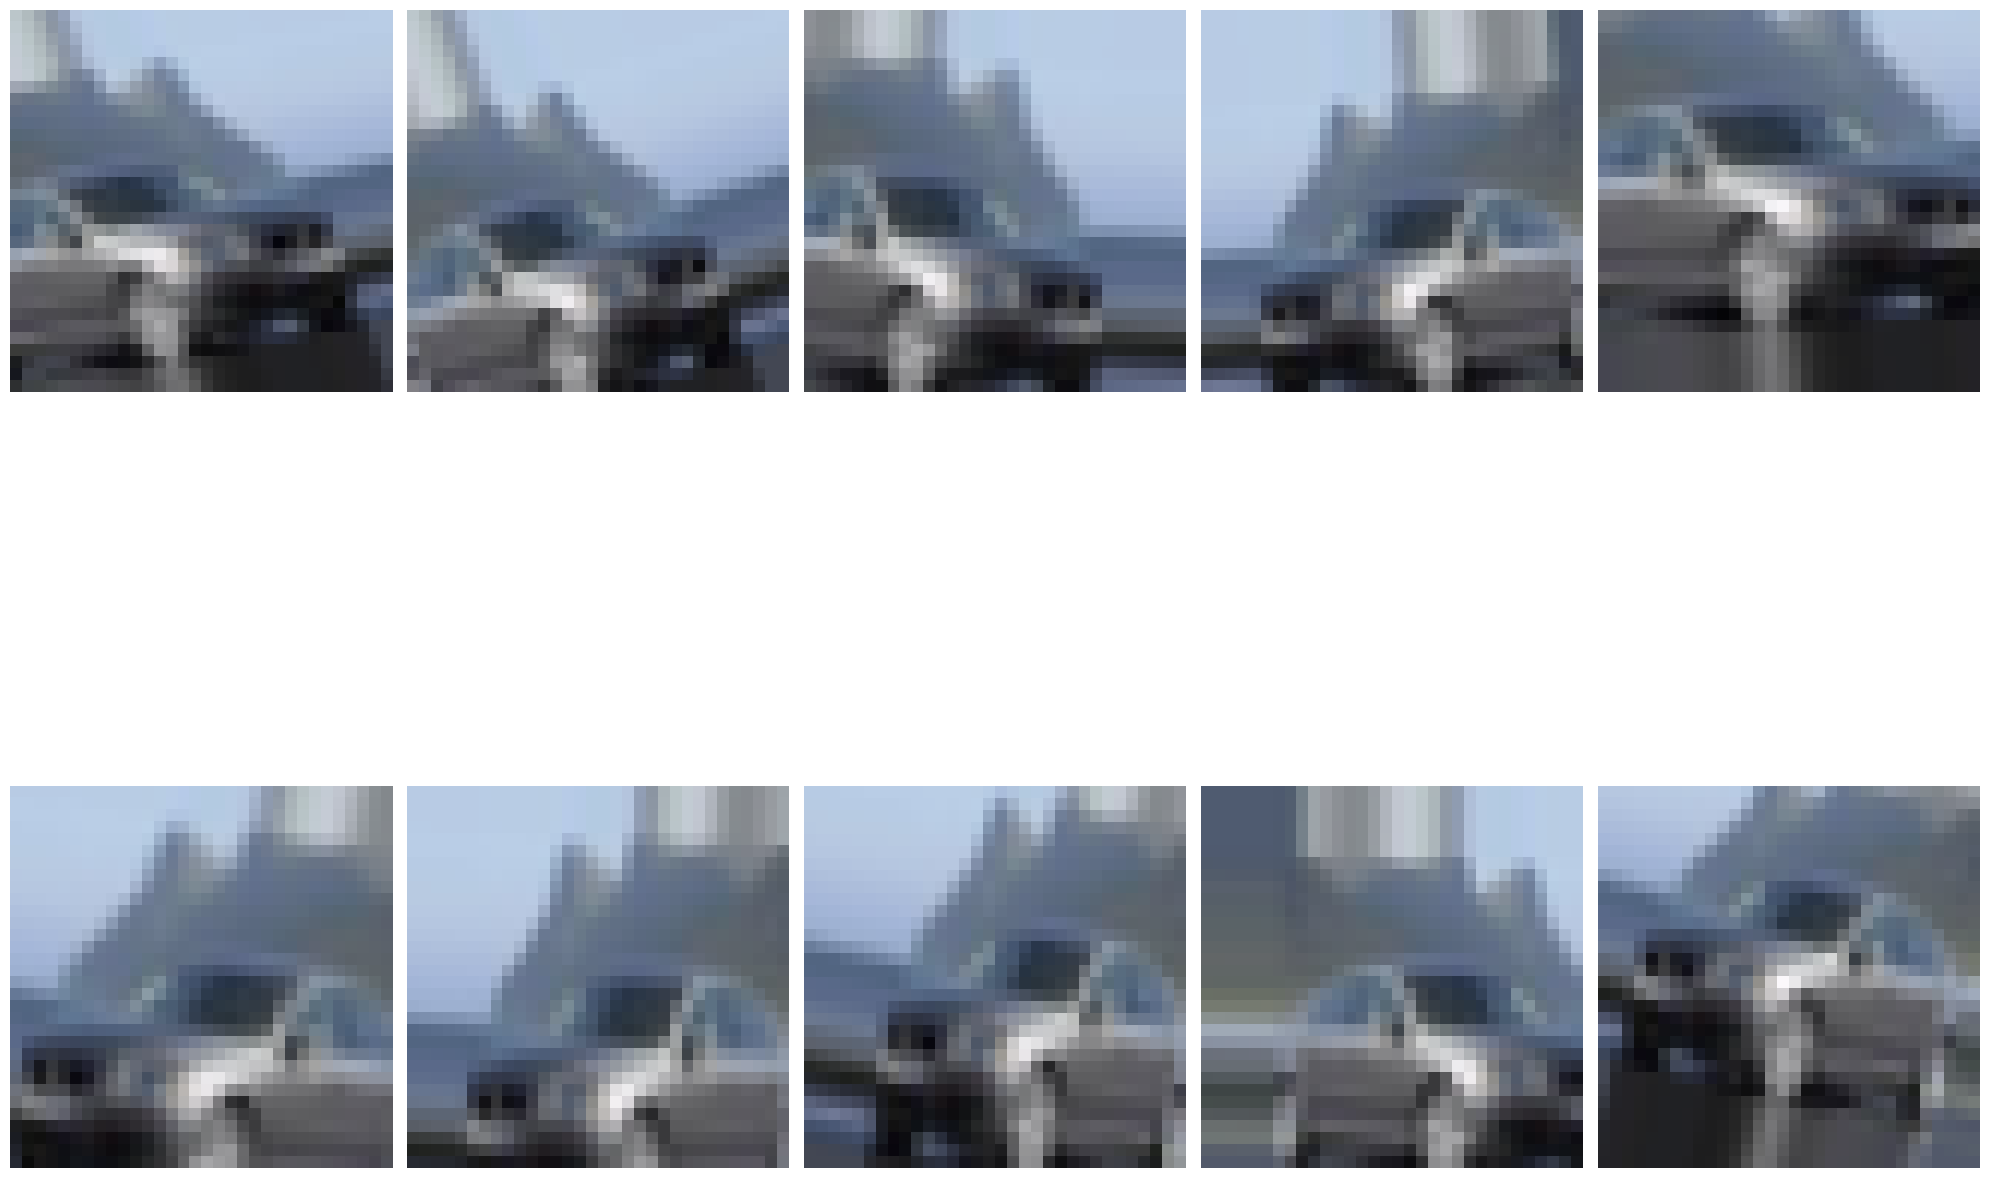

In [ ]:
# View some augmented images.
def plotImages(images_arr):
    fig, axes = plt.subplots(2, 5, figsize=(20,20))
    axes = axes.flatten()
    for img, ax in zip(images_arr, axes):
        ax.imshow(img)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

augmented_images = [train_generator[0][0][2] for i in range(10)]
plotImages(augmented_images)

## CNN Model

### Build CNN

In [ ]:
CNN_model_231867A = models.Sequential()

CNN_model_231867A.add(layers.Conv2D(32, (3, 3), activation='swish', padding='same', kernel_regularizer=regularizers.l2(0.001), input_shape=(32, 32, 3))) # Added L2 regularisation.
CNN_model_231867A.add(layers.MaxPooling2D((2, 2)))

CNN_model_231867A.add(layers.Conv2D(64, (3, 3), activation='swish', padding='same', kernel_regularizer=regularizers.l2(0.001))) # Added L2 regularisation.
CNN_model_231867A.add(layers.BatchNormalization())
CNN_model_231867A.add(layers.MaxPooling2D((2, 2)))

CNN_model_231867A.add(layers.Conv2D(128, (3, 3), activation='swish', padding='same', kernel_regularizer=regularizers.l2(0.001))) # Added L2 regularisation.
CNN_model_231867A.add(layers.BatchNormalization())
CNN_model_231867A.add(layers.MaxPooling2D((2, 2)))

CNN_model_231867A.add(layers.Conv2D(256, (3, 3), activation='swish', padding='same', kernel_regularizer=regularizers.l2(0.001))) # Added L2 regularisation.
CNN_model_231867A.add(layers.BatchNormalization())
CNN_model_231867A.add(layers.MaxPooling2D((2, 2)))

CNN_model_231867A.add(layers.GlobalAveragePooling2D()) # Replace flattening with global average pooling because it keeps lower parameters.

CNN_model_231867A.add(layers.Dense(512, activation='swish'))
CNN_model_231867A.add(Dropout(0.3)) # Added dropout of 30%.
CNN_model_231867A.add(layers.Dense(3, activation='softmax'))

print(CNN_model_231867A.summary())

/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 32, 32, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 16, 16, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 16, 16, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 16, 16, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 8, 8, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 8, 8, 128)           │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 8, 8, 128)           │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 4, 4, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 4, 4, 256)           │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 4, 4, 256)           │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 2, 2, 256)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 256)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │         131,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 3)                   │           1,539 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 523,331 (2.00 MB)

 Trainable params: 522,435 (1.99 MB)

 Non-trainable params: 896 (3.50 KB)

None


In [ ]:
from tensorflow.keras.callbacks import ReduceLROnPlateau

lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    verbose=1)

CNN_model_231867A.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
history = CNN_model_231867A.fit(train_generator,
                                epochs=30,
                                validation_data=validation_generator,
                                callbacks=[lr_scheduler])

/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 62s 613ms/step - accuracy: 0.5332 - loss: 1.3862 - val_accuracy: 0.3377 - val_loss: 1.7840 - learning_rate: 0.0010
Epoch 2/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 81s 599ms/step - accuracy: 0.6532 - loss: 1.0666 - val_accuracy: 0.3377 - val_loss: 2.4441 - learning_rate: 0.0010
Epoch 3/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 57s 602ms/step - accuracy: 0.6806 - loss: 0.9732 - val_accuracy: 0.3377 - val_loss: 2.7474 - learning_rate: 0.0010
Epoch 4/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 0s 513ms/step - accuracy: 0.7266 - loss: 0.8899
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
94/94 ━━━━━━━━━━━━━━━━━━━━ 56s 590ms/step - accuracy: 0.7266 - loss: 0.8899 - val_accuracy: 0.3781 - val_loss: 1.9596 - learning_rate: 0.0010
Epoch 5/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 52s 551ms/step - accuracy: 0.7661 - loss: 0.7763 - val_accuracy: 0.5629 - val_loss: 1.3502 - learning_rate: 5.0000e-04
Epoch 6/30
94/94 ━━━━━━━━━━━━━━━━━━━━ 59s 626ms/step - accuracy: 0.7844 - loss: 

### Evaluate CNN

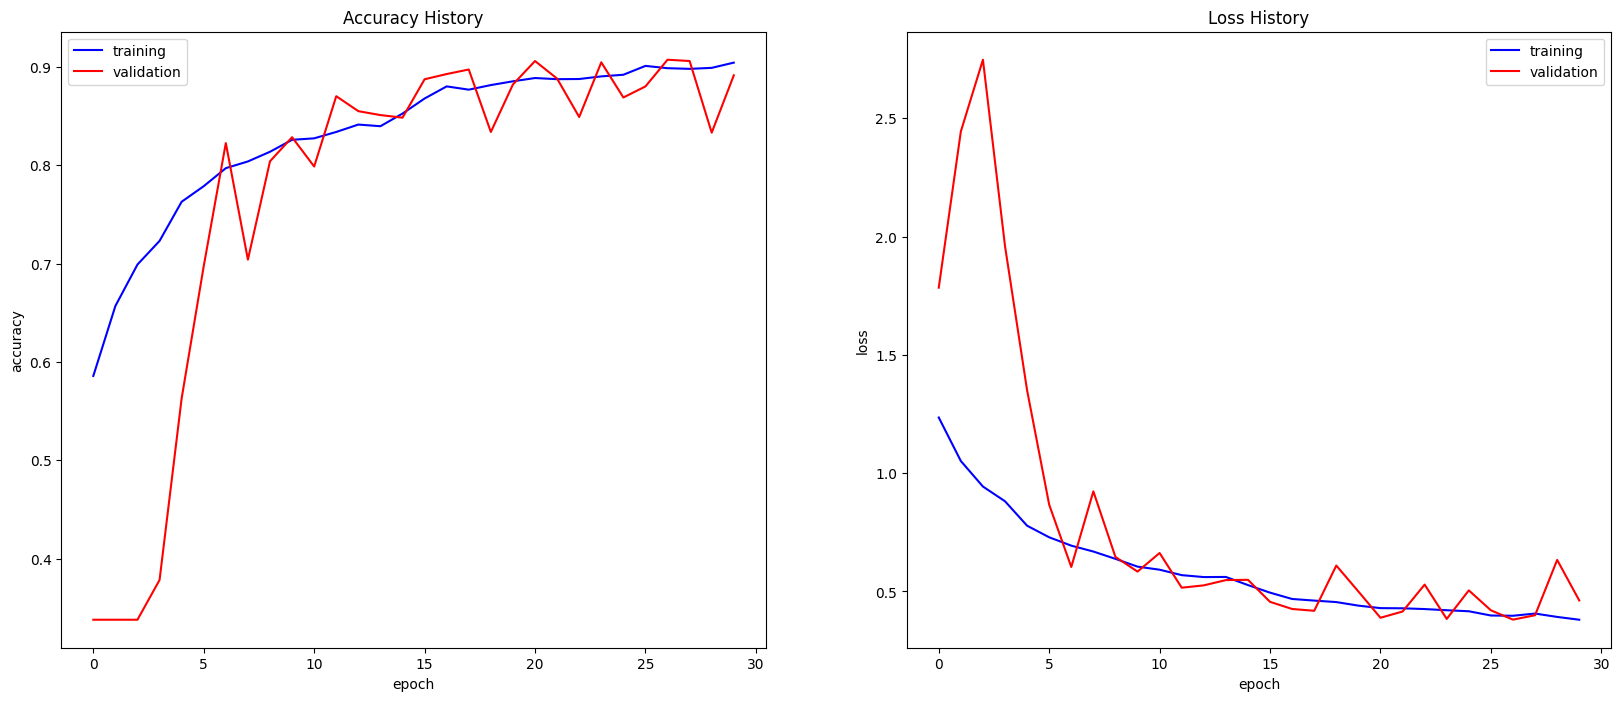

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(20, 8))
plt.subplot(1, 2, 1)
plt.plot(acc, 'b', label='Training acc')
plt.plot(val_acc, 'r', label='Validation acc')
plt.title('Accuracy History')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['training','validation'])


plt.subplot(1, 2, 2)
plt.plot(loss, 'b', label='Training loss')
plt.plot(val_loss, 'r', label='Validation loss')
plt.title('Loss History')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['training','validation'])
plt.show()

24/24 ━━━━━━━━━━━━━━━━━━━━ 8s 306ms/step


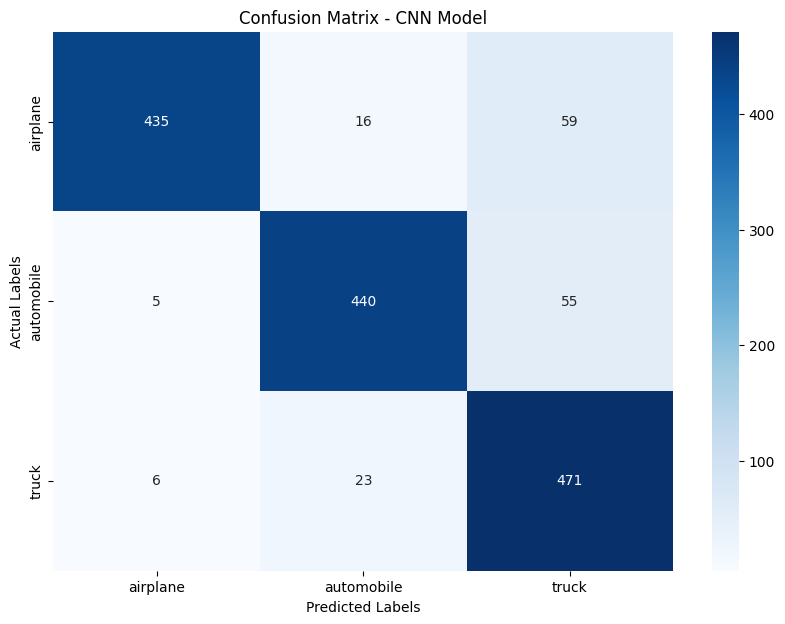

In [ ]:
# Get true labels.
y_true = validation_generator.classes

# Get class labels.
class_labels = list(validation_generator.class_indices.keys())

# Make predictions.
y_pred_probs = CNN_model_231867A.predict(validation_generator)
y_pred = np.argmax(y_pred_probs, axis=1)

# Plot confusion matrix.
conf_matrix = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 7))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)

plt.xlabel('Predicted Labels')
plt.ylabel('Actual Labels')
plt.title('Confusion Matrix - CNN Model')
plt.show()

### Prediction

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 195ms/step
Prediction: airplane


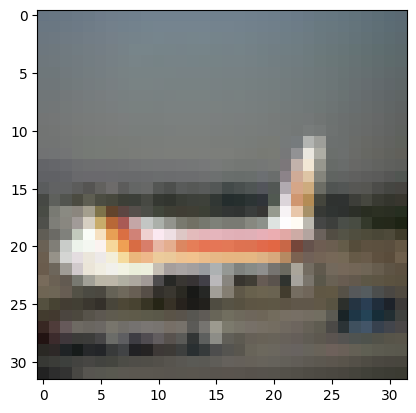

In [ ]:
# Read image "0123.png".
img = Image.open((test_directory+ 'airplane'+'//'+ "0123.png")).resize((32,32))
img = np.array(img)/255.0

# Predict class using CNN model.
result = CNN_model_231867A.predict(img[np.newaxis, ...])
predicted_class = np.argmax(result[0], axis=-1)

plt.imshow(img)

classes = ['airplane', 'automobile', 'truck']
print("Prediction:", classes[predicted_class])

## Summary of CNN Model Development

This CNN model follows a sequential design of 4 convolutional layers with increasing filter sizes, each using swish activation and L2 regularization (0.001). Padding is set to same to maintain spatial dimensions, and MaxPooling2D reduces feature map size. BatchNormalization is applied to stabilize learning. Flattening is replaced with global average pooling (GAP) to reduce parameters. The final classifer is a 512-neuron dense layer, followed by a softmax output layer of 3 classes.

Overfitting techniques used include data augmmentation like rotation to improve generalisation, L2 regularization to penalise large weight values, a dropout  layer to reduce neuron co-dependency, batchnormalization to normalise activations, and the usage of GAP to reduce model parameters.

This model uses categorical_crossentropy loss and adam optimizer. The learning rate is adjusted using ReduceLROnPlateau, reducing it by 50% if validation loss plateaus. Performance is monitored using validation accuracy and loss through graph plotting and confusion matrix evaluation.

## Transfer Learning

### Build  Model - InceptionV3

In [4]:
# Initialise ImageDataGenerator and scale pixel values to range of 0 and 1.
# Conduct data augmentation through rotation, shift, shearing, zooming, flipping.
train_image_generator = ImageDataGenerator(rescale=1./255,
                                           rotation_range=20,
                                           width_shift_range=0.2,
                                           height_shift_range=0.2,
                                           shear_range=0.2,
                                           zoom_range=0.2,
                                           horizontal_flip=True,
                                           fill_mode='nearest')

validation_image_generator = ImageDataGenerator(rescale=1./255)  # Data Augmentation is not applied for test dataset.

# Resize to 32X32 pixels, group into batches of 32.
train_generator = train_image_generator.flow_from_directory(
        train_directory,
        target_size=(96, 96),
        batch_size=32,
        shuffle=True,
        class_mode='categorical')

validation_generator = validation_image_generator.flow_from_directory(
        test_directory,
        target_size=(96, 96),
        batch_size=32,
        shuffle=False,
        class_mode='categorical')

Found 6000 images belonging to 3 classes.
Found 1510 images belonging to 3 classes.


In [5]:
from keras.applications.inception_v3 import InceptionV3

# Load base model.
base_model_231867A = InceptionV3(weights='imagenet', include_top=False, input_shape=(96, 96, 3))  # "include_top=False" to allow for custom classification.

# Redefine classification layers.
x = base_model_231867A.output
x = GlobalAveragePooling2D()(x)
x = Dense(512, activation='swish')(x)
x = Dropout(0.3)(x)
prediction = Dense(3, activation='softmax')(x)

model_231867A = Model(inputs=base_model_231867A.input, outputs=prediction)
model_231867A.summary()

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)  │ (None, 96, 96, 3)      │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d (Conv2D)           │ (None, 47, 47, 32)     │            864 │ input_layer[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization       │ (None, 47, 47, 32)     │             96 │ conv2d[0][0]           │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation (Activation)   │ (None, 47, 47, 32)     │              0 │ batch_normalization[0… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_1 (Conv2D)         │ (None, 45, 45, 32)     │          9,216 │ activation[0][0]       │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_1     │ (None, 45, 45, 32)     │             96 │ conv2d_1[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation_1 (Activation) │ (None, 45, 45, 32)     │              0 │ batch_normalization_1… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_2 (Conv2D)         │ (None, 45, 45, 64)     │         18,432 │ activation_1[0][0]     │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_2     │ (None, 45, 45, 64)     │            192 │ conv2d_2[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation_2 (Activation) │ (None, 45, 45, 64)     │              0 │ batch_normalization_2… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d             │ (None, 22, 22, 64)     │              0 │ activation_2[0][0]     │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_3 (Conv2D)         │ (None, 22, 22, 80)     │          5,120 │ max_pooling2d[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_3     │ (None, 22, 22, 80)     │            240 │ conv2d_3[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation_3 (Activation) │ (None, 22, 22, 80)     │              0 │ batch_normalization_3… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_4 (Conv2D)         │ (None, 20, 20, 192)    │        138,240 │ activation_3[0][0]     │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_4     │ (None, 20, 20, 192)    │            576 │ conv2d_4[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation_4 (Activat

 Total params: 22,853,411 (87.18 MB)

 Trainable params: 22,818,979 (87.05 MB)

 Non-trainable params: 34,432 (134.50 KB)

In [6]:
# Unfreeze base model to fine tune weights.
base_model_231867A.trainable = True

for layer in model_231867A.layers[:100]:
    layer.trainable = False

for layer in model_231867A.layers[100:]:
    layer.trainable = True

In [8]:
from tensorflow.keras.optimizers.schedules import CosineDecayRestarts

lr_scheduler = CosineDecayRestarts(
    initial_learning_rate=0.0001,
    first_decay_steps=1000,
    t_mul=2.0,
    m_mul=1.0,
    alpha=0.0,
)

optimizer = Adam(learning_rate=lr_scheduler)

model_231867A.compile(loss="categorical_crossentropy", optimizer=optimizer, metrics=["accuracy"])
history = model_231867A.fit(train_generator, epochs=15, validation_data=validation_generator)

Epoch 1/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 419s 2s/step - accuracy: 0.9069 - loss: 0.2821 - val_accuracy: 0.9450 - val_loss: 0.1532
Epoch 2/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 364s 2s/step - accuracy: 0.9271 - loss: 0.1983 - val_accuracy: 0.9510 - val_loss: 0.1414
Epoch 3/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 386s 2s/step - accuracy: 0.9378 - loss: 0.1844 - val_accuracy: 0.9523 - val_loss: 0.1343
Epoch 4/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 371s 2s/step - accuracy: 0.9296 - loss: 0.1817 - val_accuracy: 0.9517 - val_loss: 0.1331
Epoch 5/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 379s 2s/step - accuracy: 0.9321 - loss: 0.1920 - val_accuracy: 0.9517 - val_loss: 0.1322
Epoch 6/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 394s 2s/step - accuracy: 0.9390 - loss: 0.1655 - val_accuracy: 0.9523 - val_loss: 0.1384
Epoch 7/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 369s 2s/step - accuracy: 0.9370 - loss: 0.1739 - val_accuracy: 0.9536 - val_loss: 0.1367
Epoch 8/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 367s 2s/step - accuracy: 0.9419 - loss: 0.1645 - val_accu

### Evaluate Model

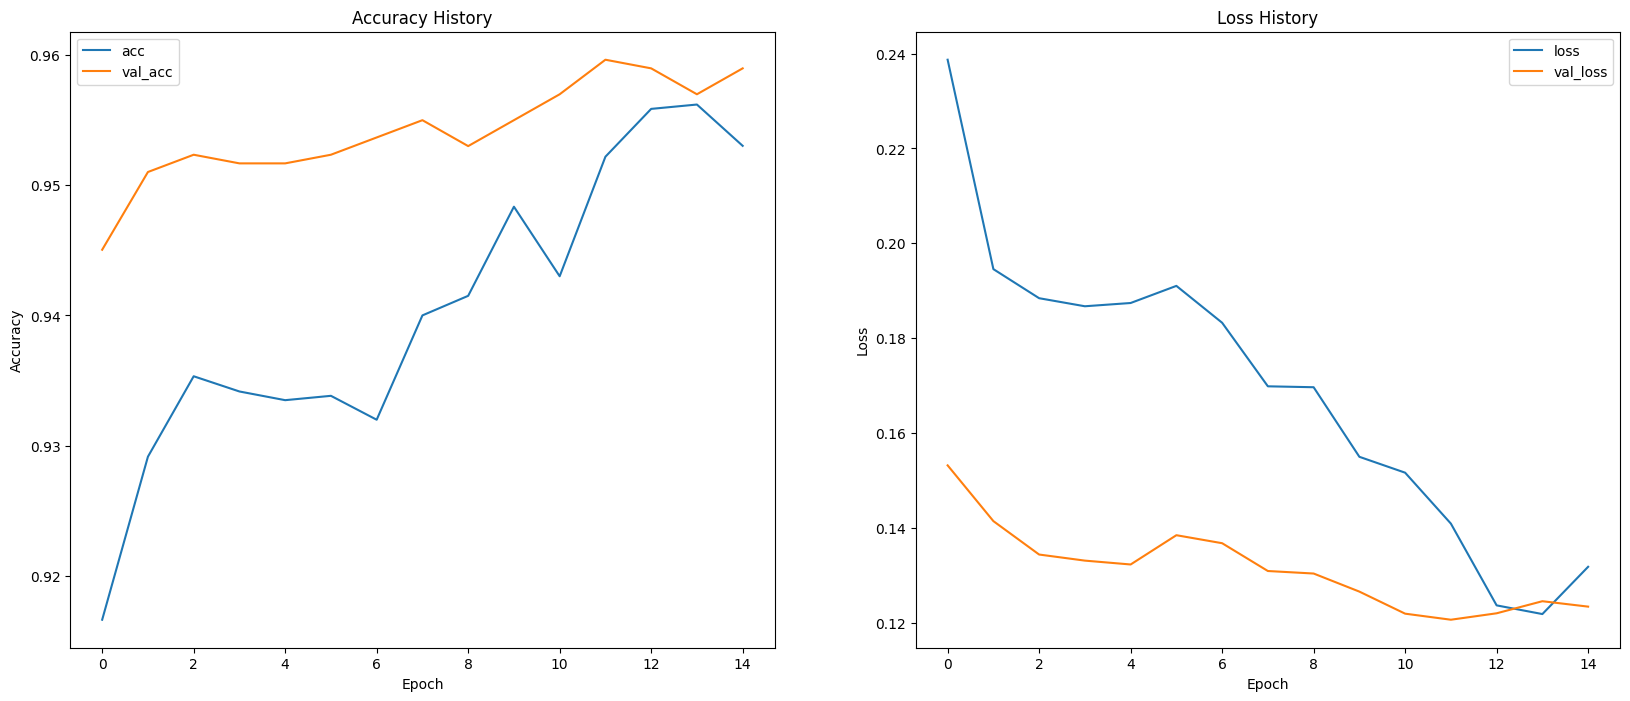

In [9]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epoch = range(len(loss))

plt.figure(figsize=(20, 8))

plt.subplot(1, 2, 1)
plt.plot(epoch,acc,label='acc')
plt.plot(epoch,val_acc,label='val_acc')
plt.title('Accuracy History')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epoch,loss,label='loss')
plt.plot(epoch,val_loss,label='val_loss')
plt.title('Loss History')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

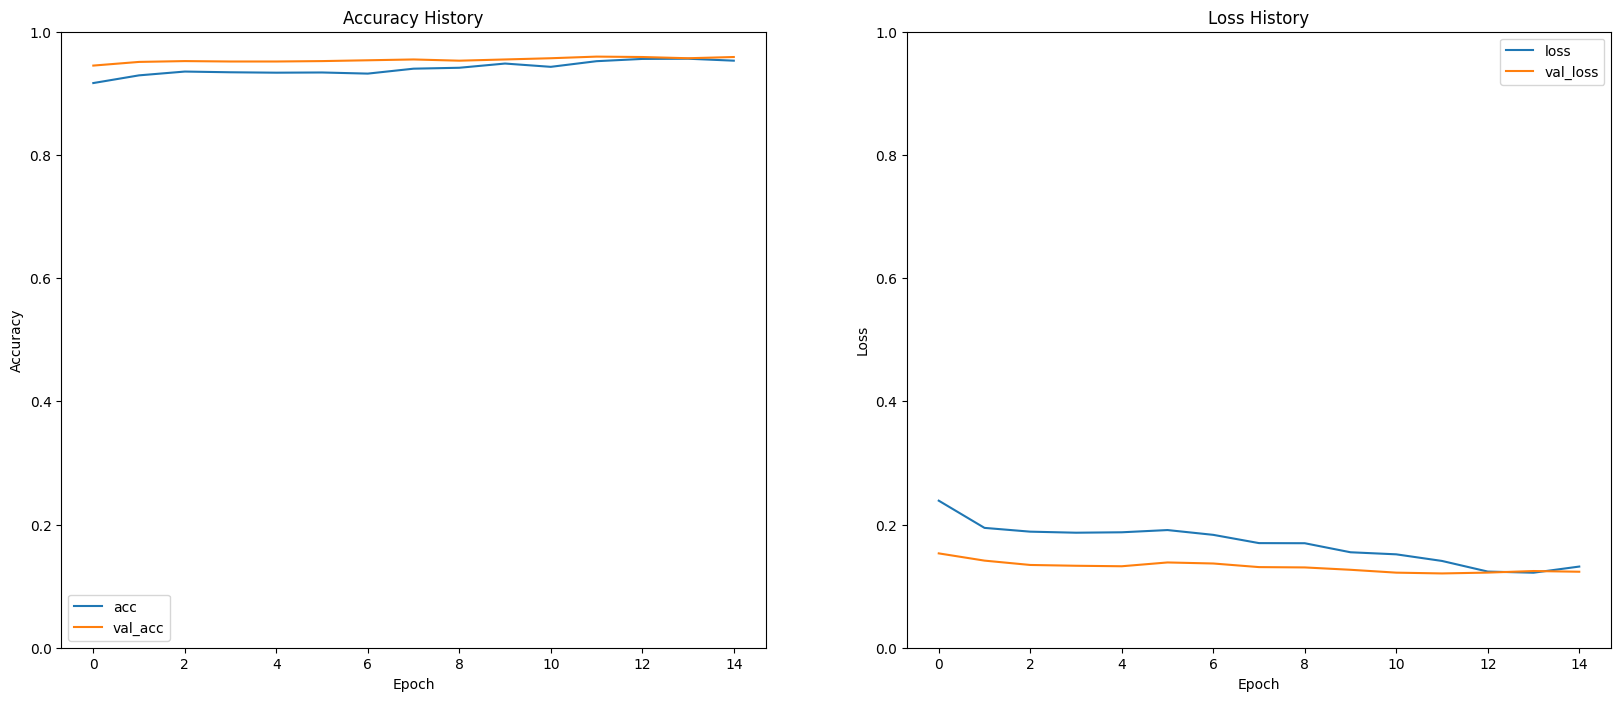

In [11]:
# View in range [0, 1].

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epoch = range(len(loss))

plt.figure(figsize=(20, 8))

plt.subplot(1, 2, 1)
plt.plot(epoch,acc,label='acc')
plt.plot(epoch,val_acc,label='val_acc')
plt.title('Accuracy History')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.ylim([0, 1])

plt.subplot(1, 2, 2)
plt.plot(epoch,loss,label='loss')
plt.plot(epoch,val_loss,label='val_loss')
plt.title('Loss History')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.ylim([0, 1])
plt.show()

48/48 ━━━━━━━━━━━━━━━━━━━━ 44s 747ms/step


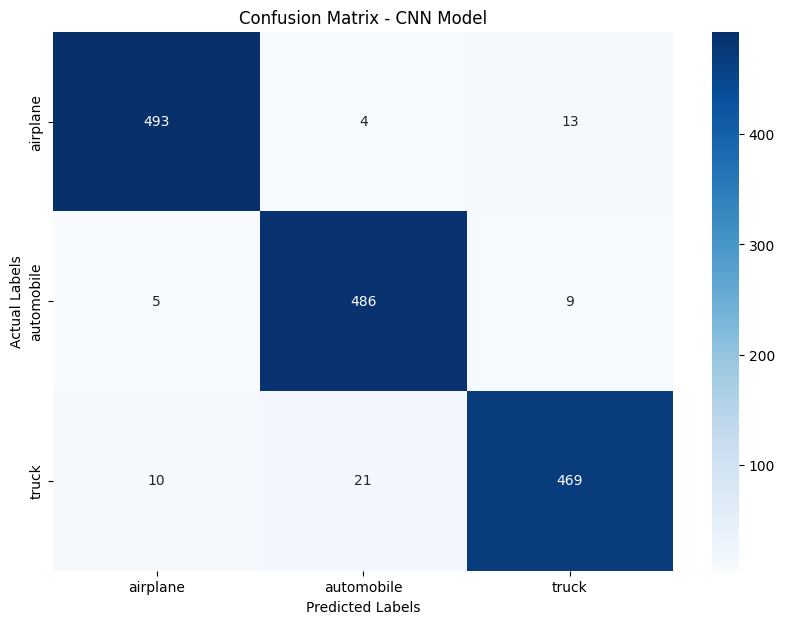

In [10]:
# Get true labels.
y_true = validation_generator.classes

# Get class labels.
class_labels = list(validation_generator.class_indices.keys())

# Make predictions.
y_pred_probs = model_231867A.predict(validation_generator)
y_pred = np.argmax(y_pred_probs, axis=1)

# Plot confusion matrix.
conf_matrix = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(10, 7))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)

plt.xlabel('Predicted Labels')
plt.ylabel('Actual Labels')
plt.title('Confusion Matrix - CNN Model')
plt.show()

### Prediction

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step
Prediction: airplane


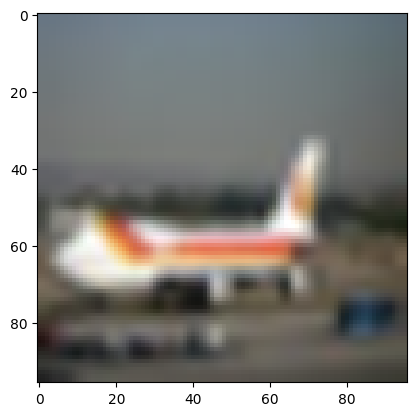

In [12]:
# Read image "0123.png".
img = Image.open((test_directory+ 'airplane'+'//'+ "0123.png")).resize((96,96))
img = np.array(img)/255.0

# Predict class using inceptionV3 model.
result = model_231867A.predict(img[np.newaxis, ...])
predicted_class = np.argmax(result[0], axis=-1)

plt.imshow(img)

classes = ['airplane', 'automobile', 'truck']
print("Prediction:", classes[predicted_class])

## Summary of Transfer Learning Model Development Model

This model uses InceptionV3. Based on the keras application website, I decided that the InceptionV3 model offers the best balance between accuracy (77.9%) and inference time (42.2ms) amongst the other models. I have to account for limited computational resources (using Colab basic) while maintaining high accuracy.

I redefined the classification layers by adding a GAP layer, a dense layer, dropout layer, and a softmax output layer. For fine-tuning, the first 100 layers remain frozen, while deeper layers are unfrozen to allow the model to adapt the learned features to the provided dataset.

To mitigate overfitting, dropout is incorporated, and a cosine decay restart scheduler is placed in adam optimiser to dynamically adjust the learning rate.
This model uses categorical_crossentropy loss and adam optimizer supplemented with a learning rate schedule. Performance is monitored using validation accuracy and loss through graph plotting and confusion matrix evaluation.

Reference: https://www.google.com/url?q=https%3A%2F%2Fkeras.io%2Fapi%2Fapplications%2F


## Comparison of the 2 models (CNN and Transfer Learning)

Final results for CNN model: accuracy: 0.9025 - loss: 0.3859 - val_accuracy: 0.8914 - val_loss: 0.4620

Final results for InceptionV3 model: accuracy: 0.9592 - loss: 0.1191 - val_accuracy: 0.9589 - val_loss: 0.1234

Ultimately, the transfer learning model performs superior to the CNN model as it demonstrates significantly higher accuracy and lower loss on both training and validation sets.

CNN offers a simpler architecture for faster training but requires more hyperparameter tuning and prone to overfitting. In contrast, transfer learning offers higher accuracy but has a more complex architecture leadiing to slower training.

My task is image classification which requires high accuracy and low loss to predict class of unseen image. Based on the better performance evidence and benefits of transfer learning (Inception V3), I conclude that transfer learning is better for my task due to performance and better generalisation ability.  
